In [1]:
%%writefile lulc_dataset.py
"""Read Sentinel-1 images and matching pixel-level land-cover labels."""

from pathlib import Path
import csv
import json

import numpy as np
import rasterio
import torch
from torch.utils.data import Dataset


class LULCDataset(Dataset):
    """Load one image/label pair at a time, keeping memory usage manageable."""

    def __init__(self, project_dir, split="train", augment=False):
        self.project_dir = Path(project_dir).resolve()
        self.augment = augment

        if split not in ("train", "validation", "test"):
            raise ValueError("Unknown dataset split.")

        if augment and split != "train":
            raise ValueError("Augmentation is only allowed for training.")

        metadata_dir = self.project_dir / "data/metadata"

        with (metadata_dir / f"{split}.csv").open(
            newline="", encoding="utf-8"
        ) as source:
            self.records = list(csv.DictReader(source))

        if not self.records:
            raise ValueError(f"The {split} split is empty.")

        with (metadata_dir / "classes.json").open(
            encoding="utf-8"
        ) as source:
            self.config = json.load(source)

        self.classes = self.config["classes"]
        self.ignore_index = self.config["ignore_index"]

        # Convert original label IDs into the model's zero-based IDs.
        self.mapping = {
            source_id: definition["id"]
            for definition in self.classes
            for source_id in definition["source_ids"]
        }

        self.ignored_source_ids = set(
            self.config["ignored_source_ids"]
        )

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        record = self.records[index]

        image_path = self.project_dir / record["image"]
        label_path = self.project_dir / record["label"]

        with rasterio.open(image_path) as source:
            image = source.read(masked=True).astype(np.float32)
            image_crs = source.crs
            image_transform = source.transform

        with rasterio.open(label_path) as source:
            raw_labels = source.read(
                self.config["label_band"], masked=True
            )
            label_crs = source.crs
            label_transform = source.transform

        if image.shape[0] != 2:
            raise ValueError(f"Expected two radar channels: {image_path}")

        if (
            image.shape[1:] != raw_labels.shape
            or image_crs is None
            or image_crs != label_crs
            or not image_transform.almost_equals(label_transform)
        ):
            raise ValueError(f"Image and label grids differ: {image_path}")

        # Identify pixels with valid values in both radar channels.
        image_values = image.filled(np.nan)
        valid_image = (
            ~np.ma.getmaskarray(image).any(axis=0)
            & np.isfinite(image_values).all(axis=0)
        )

        label_values = raw_labels.filled(0)
        valid_labels = ~np.ma.getmaskarray(raw_labels)

        observed_ids = set(
            np.unique(label_values[valid_labels]).tolist()
        )
        unknown_ids = (
            observed_ids
            - set(self.mapping)
            - self.ignored_source_ids
        )

        if unknown_ids:
            raise ValueError(f"Unknown label IDs: {unknown_ids}")

        # Missing or excluded pixels receive the ignored-target ID.
        target = np.full(
            raw_labels.shape, self.ignore_index, dtype=np.int64
        )

        for source_id, model_id in self.mapping.items():
            valid = (
                valid_image
                & valid_labels
                & (label_values == source_id)
            )
            target[valid] = model_id

        # SEN12MS baseline normalization:
        # clip existing radar values to [-25, 0], then scale to [0, 1].
        # This is NOT a conversion from linear power into dB.
        image_values = np.nan_to_num(
            image_values, nan=-25.0, posinf=0.0, neginf=-25.0
        )
        image_values = (
            np.clip(image_values, -25.0, 0.0) + 25.0
        ) / 25.0
        image_values[:, ~valid_image] = 0.0

        # Apply identical flips to imagery and labels.
        if self.augment:
            if torch.rand(()).item() < 0.5:
                image_values = np.flip(image_values, axis=2)
                target = np.flip(target, axis=1)

            if torch.rand(()).item() < 0.5:
                image_values = np.flip(image_values, axis=1)
                target = np.flip(target, axis=0)

        # Copies remove negative array strides introduced by flipping.
        return {
            "image": torch.from_numpy(image_values.copy()).float(),
            "target": torch.from_numpy(target.copy()).long(),
            "id": image_path.name,
        }

Overwriting lulc_dataset.py


In [2]:
%pip install rasterio

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
from pathlib import Path
import torch
from torch.utils.data import DataLoader
from lulc_dataset import LULCDataset

project_dir = Path.cwd()

# Start without augmentation so inspection is straightforward.
train_dataset = LULCDataset(
    project_dir,
    split="train",
    augment=False,
)

# Read four samples together. No background workers needed for this check.
loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
)

batch = next(iter(loader))

print("Training patches:", len(train_dataset))
print("Image batch shape:", tuple(batch["image"].shape))
print("Target batch shape:", tuple(batch["target"].shape))
print("Image value range:",
      batch["image"].min().item(),
      batch["image"].max().item())
print("Target IDs in this batch:",
      torch.unique(batch["target"]).tolist())
print("All image values finite:",
      torch.isfinite(batch["image"]).all().item())

valid_pixels = batch["target"] != train_dataset.ignore_index
print("Valid target pixels:", valid_pixels.sum().item())

if not valid_pixels.any():
    raise ValueError("This batch has no usable target pixels.")

print("\nPASS: the first batch is ready for a model.")

Training patches: 21782
Image batch shape: (4, 2, 256, 256)
Target batch shape: (4, 256, 256)
Image value range: 0.0 1.0
Target IDs in this batch: [2, 5, 9]
All image values finite: True
Valid target pixels: 262144

PASS: the first batch is ready for a model.


In [4]:
%%writefile lulc_model.py
"""A compact U-Net-style model for Sentinel-1 semantic segmentation."""

import torch
from torch import nn
from torch.nn import functional as F


class ConvBlock(nn.Module):
    """Two convolutions that learn spatial patterns."""

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Conv2d(
                in_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.GroupNorm(8, out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.GroupNorm(8, out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.layers(x)


class SmallUNet(nn.Module):
    """Convert two radar channels into per-pixel class scores."""

    def __init__(self, num_classes, in_channels=2):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        # Encoder: learn patterns at progressively smaller resolutions.
        self.encoder1 = ConvBlock(in_channels, 32)
        self.encoder2 = ConvBlock(32, 64)
        self.encoder3 = ConvBlock(64, 128)

        self.bottleneck = ConvBlock(128, 256)

        # Decoder: combine enlarged features with encoder features.
        self.decoder3 = ConvBlock(256 + 128, 128)
        self.decoder2 = ConvBlock(128 + 64, 64)
        self.decoder1 = ConvBlock(64 + 32, 32)

        # One output score per class at every pixel.
        self.output = nn.Conv2d(32, num_classes, kernel_size=1)

    @staticmethod
    def combine(features, skip):
        features = F.interpolate(
            features,
            size=skip.shape[-2:],
            mode="bilinear",
            align_corners=False,
        )
        return torch.cat([features, skip], dim=1)

    def forward(self, x):
        e1 = self.encoder1(x)
        e2 = self.encoder2(self.pool(e1))
        e3 = self.encoder3(self.pool(e2))

        center = self.bottleneck(self.pool(e3))

        d3 = self.decoder3(self.combine(center, e3))
        d2 = self.decoder2(self.combine(d3, e2))
        d1 = self.decoder1(self.combine(d2, e1))

        # Return raw scores. CrossEntropyLoss handles their conversion.
        return self.output(d1)

Overwriting lulc_model.py


In [5]:
import lulc_model
import inspect

print("Available model classes:")

for name, obj in vars(lulc_model).items():
    if inspect.isclass(obj) and obj.__module__ == lulc_model.__name__:
        print(" -", name, inspect.signature(obj))

Available model classes:
 - ConvBlock (in_channels, out_channels)
 - SmallUNet (num_classes, in_channels=2)


In [6]:
import torch
import torch.nn.functional as F
from lulc_model import SmallUNet

torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Number of model output classes
num_classes = len(train_dataset.classes)

print("Number of classes:", num_classes)
print("Classes:", train_dataset.classes)
print("Ignore index:", train_dataset.ignore_index)

# Build model
model = SmallUNet(
    num_classes=num_classes,
    in_channels=2
).to(device)

# Move the already-loaded batch to GPU
images = batch["image"].to(device)
targets = batch["target"].to(device)

print("Input shape:", tuple(images.shape))
print("Target shape:", tuple(targets.shape))

# Forward pass
with torch.no_grad():
    scores = model(images)

print("Model output shape:", tuple(scores.shape))

# Check expected spatial dimensions
if scores.shape[0] != images.shape[0]:
    raise ValueError("Batch dimension changed.")

if scores.shape[1] != num_classes:
    raise ValueError(
        f"Expected {num_classes} output classes, got {scores.shape[1]}"
    )

if scores.shape[2:] != targets.shape[1:]:
    raise ValueError(
        f"Output spatial shape {scores.shape[2:]} "
        f"does not match target shape {targets.shape[1:]}"
    )

# Cross-entropy loss
loss = F.cross_entropy(
    scores,
    targets,
    ignore_index=train_dataset.ignore_index
)

print("Initial loss:", float(loss))

print("\nPASS: model forward pass and loss calculation work.")

Device: cuda
GPU: NVIDIA RTX A6000
Number of classes: 10
Classes: [{'id': 0, 'name': 'Forest', 'source_ids': [1, 2, 3, 4, 5]}, {'id': 1, 'name': 'Shrubland', 'source_ids': [6, 7]}, {'id': 2, 'name': 'Savanna', 'source_ids': [8, 9]}, {'id': 3, 'name': 'Grassland', 'source_ids': [10]}, {'id': 4, 'name': 'Wetland', 'source_ids': [11]}, {'id': 5, 'name': 'Cropland', 'source_ids': [12, 14]}, {'id': 6, 'name': 'Urban/Built-up', 'source_ids': [13]}, {'id': 7, 'name': 'Snow/Ice', 'source_ids': [15]}, {'id': 8, 'name': 'Barren', 'source_ids': [16]}, {'id': 9, 'name': 'Water', 'source_ids': [17]}]
Ignore index: 255
Input shape: (4, 2, 256, 256)
Target shape: (4, 256, 256)
Model output shape: (4, 10, 256, 256)
Initial loss: 2.5461907386779785

PASS: model forward pass and loss calculation work.


In [7]:
from pathlib import Path
import csv
import json
import random

import torch
from torch import nn
from torch.utils.data import DataLoader, Subset

from lulc_dataset import LULCDataset
from lulc_model import SmallUNet

# Reproducible starting point.
SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

project_dir = Path.cwd()
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Separate dataset objects ensure validation receives no augmentation.
train_data = LULCDataset(
    project_dir, split="train", augment=True
)
validation_data = LULCDataset(
    project_dir, split="validation", augment=False
)

# Small, fixed subsets for checking the training pipeline only.
train_indices = random.Random(SEED).sample(
    range(len(train_data)), min(256, len(train_data))
)
validation_indices = random.Random(SEED + 1).sample(
    range(len(validation_data)), min(64, len(validation_data))
)

generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    Subset(train_data, train_indices),
    batch_size=8,
    shuffle=True,
    num_workers=0,
    generator=generator,
)

validation_loader = DataLoader(
    Subset(validation_data, validation_indices),
    batch_size=8,
    shuffle=False,
    num_workers=0,
)

# Start fresh rather than reuse the model from the wiring check.
model = SmallUNet(
    num_classes=len(train_data.classes)
).to(device)

criterion = nn.CrossEntropyLoss(
    ignore_index=train_data.ignore_index,
    reduction="sum",
)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)


def run_epoch(loader, training):
    """Return loss per valid pixel and pixel accuracy."""
    model.train(training)

    loss_sum = 0.0
    correct_pixels = 0
    valid_pixels = 0

    with torch.set_grad_enabled(training):
        for batch in loader:
            images = batch["image"].to(device)
            targets = batch["target"].to(device)

            valid = targets != train_data.ignore_index
            count = int(valid.sum().item())

            # A completely missing-label batch cannot teach the model.
            if count == 0:
                continue

            if training:
                optimizer.zero_grad(set_to_none=True)

            scores = model(images)
            summed_loss = criterion(scores, targets)
            mean_loss = summed_loss / count

            if not torch.isfinite(mean_loss).item():
                raise RuntimeError("Non-finite loss encountered.")

            if training:
                mean_loss.backward()
                optimizer.step()

            predictions = scores.detach().argmax(dim=1)

            loss_sum += summed_loss.detach().item()
            correct_pixels += int(
                ((predictions == targets) & valid).sum().item()
            )
            valid_pixels += count

    if valid_pixels == 0:
        raise RuntimeError("No valid target pixels found in this epoch.")

    return (
        loss_sum / valid_pixels,
        correct_pixels / valid_pixels,
    )


# Use a unique folder so previous experiments are preserved.
from datetime import datetime, timezone

run_name = datetime.now(timezone.utc).strftime(
    "pipeline_check_%Y%m%d_%H%M%S_%f"
)
run_dir = project_dir / "results" / run_name
run_dir.mkdir(parents=True, exist_ok=False)

# Save enough information to identify exactly what this run used.
configuration = {
    "purpose": "small training pipeline check, not final evaluation",
    "seed": SEED,
    "epochs": 3,
    "batch_size": 8,
    "learning_rate": 0.001,
    "optimizer": "Adam",
    "loss": "unweighted cross entropy over valid pixels",
    "train_indices": train_indices,
    "validation_indices": validation_indices,
    "class_configuration": train_data.config,
    "normalization": "clip existing values to [-25, 0], scale to [0, 1]",
    "torch_version": str(torch.__version__),
}

with (run_dir / "configuration.json").open(
    "w", encoding="utf-8"
) as output:
    json.dump(configuration, output, indent=2)

history = []
best_validation_loss = float("inf")

print("Device:", device)
print("Training sample:", len(train_indices), "patches")
print("Validation sample:", len(validation_indices), "patches")
print("Output folder:", run_dir)
print("Starting training...", flush=True)

for epoch in range(1, 4):
    train_loss, train_accuracy = run_epoch(
        train_loader, training=True
    )
    validation_loss, validation_accuracy = run_epoch(
        validation_loader, training=False
    )

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "validation_loss": validation_loss,
        "train_accuracy": train_accuracy,
        "validation_accuracy": validation_accuracy,
    }
    history.append(row)

    # Save results after each completed epoch.
    with (run_dir / "history.csv").open(
        "w", newline="", encoding="utf-8"
    ) as output:
        writer = csv.DictWriter(output, fieldnames=list(row))
        writer.writeheader()
        writer.writerows(history)

    if validation_loss < best_validation_loss:
        best_validation_loss = validation_loss

        checkpoint = {
            "model_state_dict": model.state_dict(),
            "num_classes": len(train_data.classes),
            "epoch": epoch,
            "validation_loss": validation_loss,
            "class_configuration": train_data.config,
        }

        temporary_path = run_dir / "best_model.pt.part"
        torch.save(checkpoint, temporary_path)
        temporary_path.replace(run_dir / "best_model.pt")

    print(
        f"Epoch {epoch}/3 | "
        f"train loss {train_loss:.4f} | "
        f"validation loss {validation_loss:.4f} | "
        f"train accuracy {train_accuracy:.1%} | "
        f"validation accuracy {validation_accuracy:.1%}",
        flush=True,
    )

print("\nFinished. Saved history, configuration, and best checkpoint.")

Device: cuda
Training sample: 256 patches
Validation sample: 64 patches
Output folder: /home/jovyan/vault/DeepLearningPro/results/pipeline_check_20261109_071039_424141
Starting training...
Epoch 1/3 | train loss 2.1256 | validation loss 2.1508 | train accuracy 21.6% | validation accuracy 16.0%
Epoch 2/3 | train loss 2.0270 | validation loss 2.1146 | train accuracy 23.0% | validation accuracy 16.0%
Epoch 3/3 | train loss 1.9755 | validation loss 1.9768 | train accuracy 23.1% | validation accuracy 23.3%

Finished. Saved history, configuration, and best checkpoint.


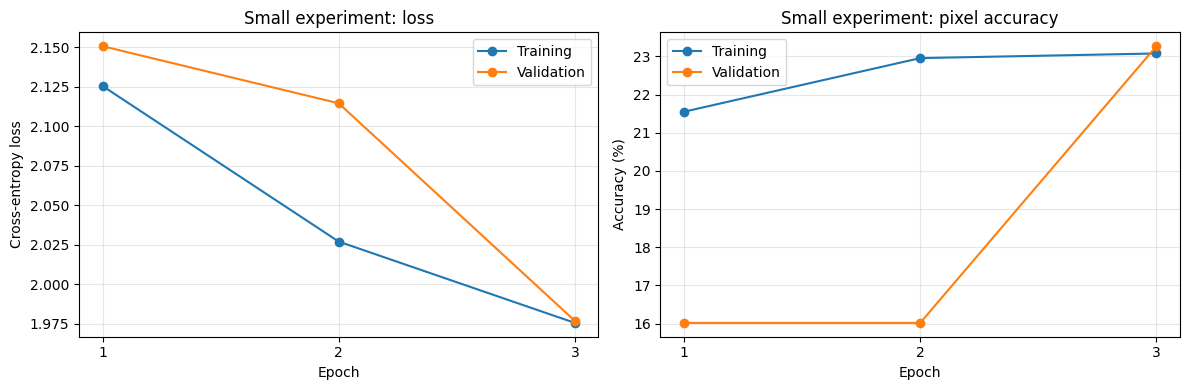

In [8]:
import matplotlib.pyplot as plt

epochs = [row["epoch"] for row in history]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    epochs,
    [row["train_loss"] for row in history],
    marker="o",
    label="Training",
)
axes[0].plot(
    epochs,
    [row["validation_loss"] for row in history],
    marker="o",
    label="Validation",
)
axes[0].set_title("Small experiment: loss")
axes[0].set_ylabel("Cross-entropy loss")

axes[1].plot(
    epochs,
    [100 * row["train_accuracy"] for row in history],
    marker="o",
    label="Training",
)
axes[1].plot(
    epochs,
    [100 * row["validation_accuracy"] for row in history],
    marker="o",
    label="Validation",
)
axes[1].set_title("Small experiment: pixel accuracy")
axes[1].set_ylabel("Accuracy (%)")

for axis in axes:
    axis.set_xlabel("Epoch")
    axis.set_xticks(epochs)
    axis.legend()
    axis.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(run_dir / "training_curves.png", dpi=150)
plt.show()

In [9]:
import torch
import numpy as np

# Load the best checkpoint from this small experiment.
checkpoint = torch.load(
    run_dir / "best_model.pt",
    map_location=device,
    weights_only=True,
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

num_classes = len(train_data.classes)

# Rows = reference classes; columns = predicted classes.
confusion = torch.zeros(
    (num_classes, num_classes), dtype=torch.int64
)

with torch.inference_mode():
    for batch in validation_loader:
        images = batch["image"].to(device)
        targets = batch["target"].to(device)

        predictions = model(images).argmax(dim=1)
        valid = targets != train_data.ignore_index

        encoded = (
            targets[valid] * num_classes + predictions[valid]
        )

        confusion += torch.bincount(
            encoded,
            minlength=num_classes * num_classes,
        ).reshape(num_classes, num_classes).cpu()

matrix = confusion.numpy()
reference_counts = matrix.sum(axis=1)
prediction_counts = matrix.sum(axis=0)
true_positives = np.diag(matrix)
union = reference_counts + prediction_counts - true_positives

# Undefined scores remain NaN rather than being silently set to zero.
iou = np.divide(
    true_positives,
    union,
    out=np.full(num_classes, np.nan),
    where=union > 0,
)

total = matrix.sum()
if total == 0:
    raise ValueError("No valid validation pixels found.")

print("Best checkpoint epoch:", checkpoint["epoch"])
print(f"Validation-sample accuracy: {true_positives.sum() / total:.2%}")
print("\nClass             Reference %  Predicted %    IoU")

for definition in train_data.classes:
    class_id = definition["id"]
    score = (
        f"{iou[class_id]:.3f}"
        if np.isfinite(iou[class_id])
        else "N/A"
    )

    print(
        f"{definition['name']:17} "
        f"{100 * reference_counts[class_id] / total:10.2f}% "
        f"{100 * prediction_counts[class_id] / total:10.2f}% "
        f"{score:>7}"
    )

np.save(run_dir / "validation_sample_confusion.npy", matrix)

print("\nSaved the validation-sample confusion matrix.")
print("These are preliminary sample results, not final test metrics.")

Best checkpoint epoch: 3
Validation-sample accuracy: 23.27%

Class             Reference %  Predicted %    IoU
Forest                 13.44%       0.00%   0.000
Shrubland               0.37%       0.00%   0.000
Savanna                16.02%      79.11%   0.201
Grassland              26.96%       2.73%   0.021
Wetland                 0.49%       0.00%   0.000
Cropland               15.68%       0.45%   0.000
Urban/Built-up          9.72%       0.00%   0.000
Snow/Ice                0.00%       0.00%     N/A
Barren                 12.55%      17.70%   0.285
Water                   4.77%       0.00%   0.000

Saved the validation-sample confusion matrix.
These are preliminary sample results, not final test metrics.


In [10]:
from pathlib import Path
from itertools import combinations
import csv

import rasterio
from rasterio.warp import transform_bounds

project_dir = Path.cwd()
metadata_dir = project_dir / "data/metadata"

scene_bounds = {}

for split in ("train", "validation", "test"):
    with (metadata_dir / f"{split}.csv").open(
        newline="", encoding="utf-8"
    ) as source:
        records = list(csv.DictReader(source))

    print(
        f"Reading {split}: {len(records):,} image footprints",
        flush=True,
    )

    for index, record in enumerate(records, start=1):
        image_path = project_dir / record["image"]

        with rasterio.open(image_path) as source:
            if source.crs is None:
                raise ValueError(f"Missing coordinate system: {image_path}")

            west, south, east, north = transform_bounds(
                source.crs,
                "EPSG:4326",
                *source.bounds,
                densify_pts=21,
            )

        # This simple rectangle audit cannot handle dateline crossings.
        if east < west or east - west > 180:
            raise ValueError(
                f"Dateline-sensitive footprint needs separate checking: "
                f"{image_path}"
            )

        key = (split, record["scene"])

        if key not in scene_bounds:
            scene_bounds[key] = [west, south, east, north]
        else:
            previous = scene_bounds[key]
            scene_bounds[key] = [
                min(previous[0], west),
                min(previous[1], south),
                max(previous[2], east),
                max(previous[3], north),
            ]

        if index % 5000 == 0:
            print(f"  Read {index:,} footprints", flush=True)

footprints = []

for (split, scene), bounds in sorted(scene_bounds.items()):
    footprints.append({
        "split": split,
        "scene": scene,
        "west": bounds[0],
        "south": bounds[1],
        "east": bounds[2],
        "north": bounds[3],
    })

with (metadata_dir / "scene_footprints.csv").open(
    "w", newline="", encoding="utf-8"
) as output:
    writer = csv.DictWriter(
        output,
        fieldnames=["split", "scene", "west", "south", "east", "north"],
    )
    writer.writeheader()
    writer.writerows(footprints)


def rectangles_overlap(a, b):
    """Check positive-area overlap; touching edges do not count."""
    return (
        max(a["west"], b["west"]) < min(a["east"], b["east"])
        and max(a["south"], b["south"]) < min(a["north"], b["north"])
    )


flags = []

for first, second in combinations(footprints, 2):
    if first["split"] == second["split"]:
        continue

    if rectangles_overlap(first, second):
        flags.append({
            "first_split": first["split"],
            "first_scene": first["scene"],
            "second_split": second["split"],
            "second_scene": second["scene"],
        })

with (metadata_dir / "split_overlap_flags.csv").open(
    "w", newline="", encoding="utf-8"
) as output:
    writer = csv.DictWriter(
        output,
        fieldnames=[
            "first_split", "first_scene",
            "second_split", "second_scene",
        ],
    )
    writer.writeheader()
    writer.writerows(flags)

print("\nScenes checked:", len(footprints))
print("Cross-split rectangle overlaps:", len(flags))

for flag in flags[:20]:
    print(
        f"{flag['first_split']}/{flag['first_scene']} overlaps "
        f"{flag['second_split']}/{flag['second_scene']}"
    )

if not flags:
    print("No cross-split scene bounding rectangles overlap.")
else:
    print("Inspect these flags before using the current splits.")

print("Saved scene_footprints.csv and split_overlap_flags.csv.")

Reading train: 21,782 image footprints
  Read 5,000 footprints
  Read 10,000 footprints
  Read 15,000 footprints
  Read 20,000 footprints
Reading validation: 4,993 image footprints
Reading test: 5,050 image footprints
  Read 5,000 footprints

Scenes checked: 46
Cross-split rectangle overlaps: 0
No cross-split scene bounding rectangles overlap.
Saved scene_footprints.csv and split_overlap_flags.csv.


In [11]:
from pathlib import Path
import sys

print("Current folder:", Path.cwd())
print("Training script found:", Path("train_baseline.py").is_file())
print("Python:", sys.version.split()[0])

try:
    import torch
    print("PyTorch:", torch.__version__)
    print("GPU available:", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
except ImportError:
    print("PyTorch is missing from this environment.")

Current folder: /home/jovyan/vault/DeepLearningPro
Training script found: True
Python: 3.11.13
PyTorch: 2.9.1+cu128
GPU available: True
GPU: NVIDIA RTX A6000


In [12]:
%run train_baseline.py --epochs 10 --batch-size 8

Device: cuda | Training: 21782 | Validation: 4993
Results: /home/jovyan/vault/DeepLearningPro/results/winter9_20261109_071235_334316

Epoch 1/10
  train 1/2723 | loss 2.2818 | elapsed 0.0 min
  train 100/2723 | loss 2.0188 | elapsed 0.5 min
  train 200/2723 | loss 1.9395 | elapsed 1.3 min
  train 300/2723 | loss 1.8817 | elapsed 1.9 min
  train 400/2723 | loss 1.8278 | elapsed 2.4 min
  train 500/2723 | loss 1.7784 | elapsed 2.8 min
  train 600/2723 | loss 1.7428 | elapsed 3.3 min
  train 700/2723 | loss 1.7044 | elapsed 3.8 min
  train 800/2723 | loss 1.6783 | elapsed 4.3 min
  train 900/2723 | loss 1.6516 | elapsed 5.0 min
  train 1000/2723 | loss 1.6336 | elapsed 5.5 min
  train 1100/2723 | loss 1.6106 | elapsed 5.9 min
  train 1200/2723 | loss 1.5949 | elapsed 7.2 min
  train 1300/2723 | loss 1.5835 | elapsed 8.2 min
  train 1400/2723 | loss 1.5717 | elapsed 10.5 min
  train 1500/2723 | loss 1.5587 | elapsed 10.9 min
  train 1600/2723 | loss 1.5495 | elapsed 11.4 min
  train 1700/2

In [19]:
from pathlib import Path

results_dir = Path("results")

print("=== RESULTS DIRECTORIES ===")
for p in sorted(results_dir.iterdir(), key=lambda x: x.stat().st_mtime, reverse=True):
    if p.is_dir():
        print(p)

print("\n=== WEIGHTS ===")
for p in sorted(Path("weights").glob("*")):
    print(p, f"({p.stat().st_size / 1024 / 1024:.1f} MB)")

=== RESULTS DIRECTORIES ===
results/winter9_20261109_071235_334316
results/pipeline_check_20261109_071039_424141
results/winter9_20261106_094944_502500
results/winter9_20261106_114313_372365
results/pipeline_check_20261106_094753_784931
results/pipeline_check_20261106_093423_629318
results/winter9_20261105_191332_022578
results/winter9_20261105_191315_589748
results/winter9_20261105_183238_534986
results/winter9_20261105_183145_476017
results/pipeline_check_20261105_182938_971034
results/pipeline_check_20261105_152836_552495

=== WEIGHTS ===


In [13]:
import shutil
import subprocess

command = shutil.which("nvidia-smi")

if command is None:
    print("nvidia-smi is not available in this workspace.")
else:
    result = subprocess.run(
        [command],
        capture_output=True,
        text=True,
        timeout=30,
    )
    print(result.stdout)
    print(result.stderr)

Mon Nov  9 09:10:32 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX A6000               Off |   00000000:01:00.0 Off |                  Off |
| 35%   60C    P2            164W /  300W |    8117MiB /  49140MiB |     27%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [14]:
%pip install rasterio matplotlib

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [15]:
import torch
import rasterio
import matplotlib
from pathlib import Path

print("Rasterio:", rasterio.__version__)
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
print("Training script found:", Path("train_baseline.py").is_file())

# Check that both project modules now import.
from lulc_dataset import LULCDataset
from lulc_model import SmallUNet

print("Project modules imported successfully.")

Rasterio: 1.4.4
PyTorch: 2.9.1+cu128
GPU available: True
Training script found: True
Project modules imported successfully.


Completed epochs: 10
Best epoch by validation mIoU: 9
Best validation mIoU: 29.88%
Accuracy at that epoch: 53.37%
Best checkpoint epoch: 9

Per-class results from the best validation checkpoint:
Forest            IoU: 0.268 | F1: 0.423
Shrubland         IoU: 0.002 | F1: 0.004
Savanna           IoU: 0.401 | F1: 0.573
Grassland         IoU: 0.422 | F1: 0.594
Wetland           IoU: 0.057 | F1: 0.108
Cropland          IoU: 0.245 | F1: 0.394
Urban/Built-up    IoU: 0.634 | F1: 0.776
Barren            IoU: 0.250 | F1: 0.400
Water             IoU: 0.409 | F1: 0.581


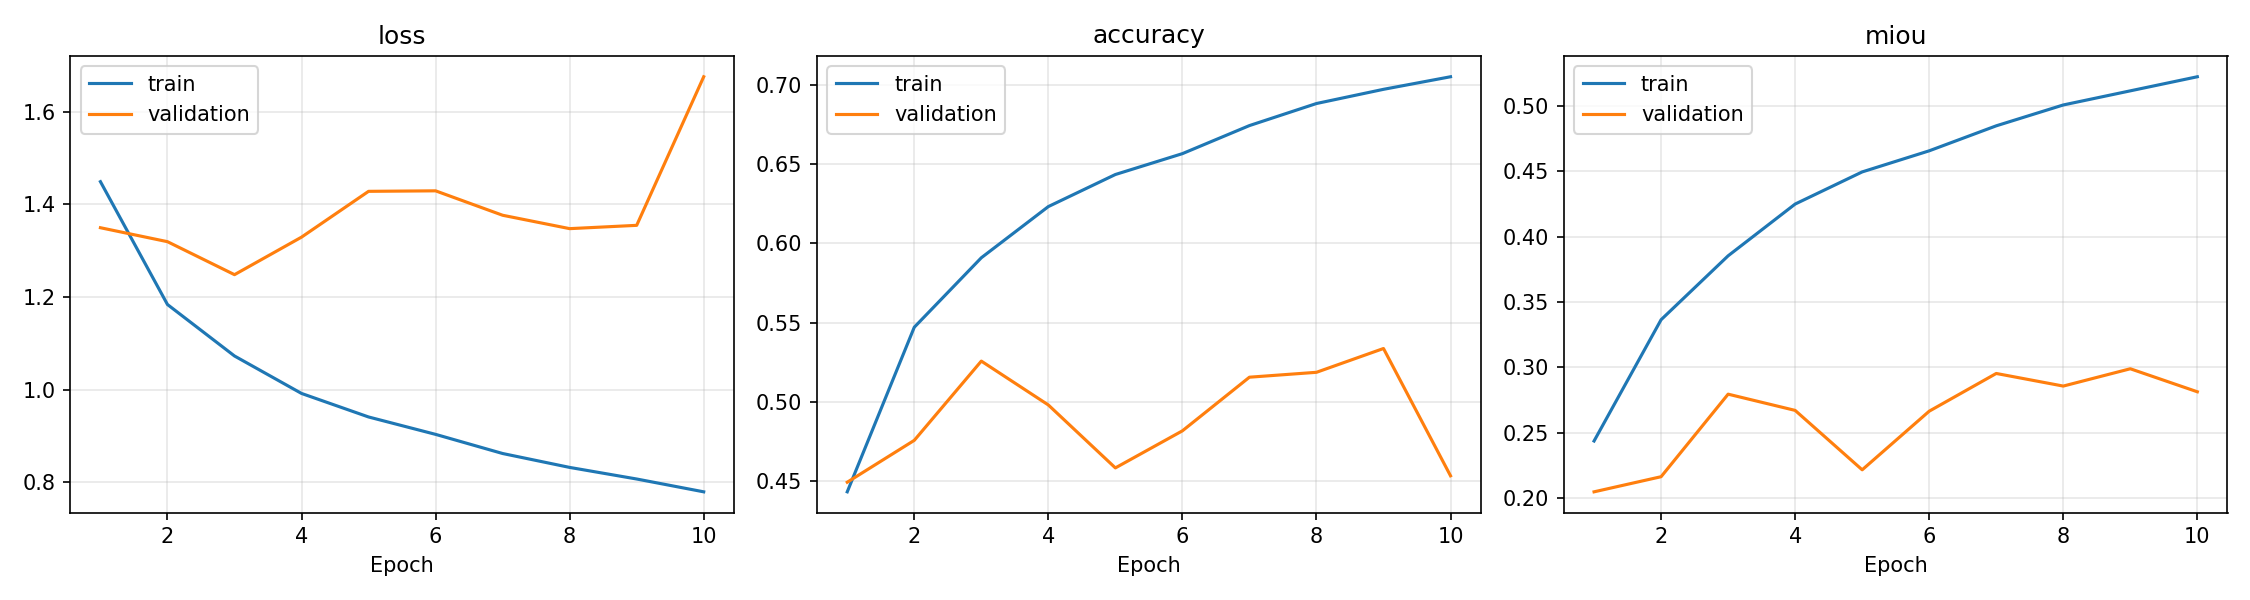

In [16]:
from pathlib import Path
import csv
import torch
from IPython.display import display, Image

# This is the completed run shown in your screenshot.
run_dir = Path("results/winter9_20261106_094944_502500")

if not run_dir.is_dir():
    raise FileNotFoundError(f"Run folder not found: {run_dir}")

with (run_dir / "history.csv").open(
    newline="", encoding="utf-8"
) as source:
    history = list(csv.DictReader(source))

if not history:
    raise ValueError("The history file contains no completed epochs.")

best_row = max(
    history,
    key=lambda row: float(row["validation_miou"]),
)

print("Completed epochs:", len(history))
print("Best epoch by validation mIoU:", best_row["epoch"])
print(
    "Best validation mIoU:",
    f"{float(best_row['validation_miou']):.2%}",
)
print(
    "Accuracy at that epoch:",
    f"{float(best_row['validation_accuracy']):.2%}",
)

# Read the saved checkpoint on CPU to verify its recorded epoch.
checkpoint = torch.load(
    run_dir / "best_model.pt",
    map_location="cpu",
    weights_only=True,
)

print("Best checkpoint epoch:", checkpoint["epoch"])

if int(best_row["epoch"]) != checkpoint["epoch"]:
    raise ValueError("History and checkpoint epochs do not match.")

print("\nPer-class results from the best validation checkpoint:")

with (run_dir / "best_validation_classes.csv").open(
    newline="", encoding="utf-8"
) as source:
    for row in csv.DictReader(source):
        print(
            f"{row['class_name']:17} "
            f"IoU: {float(row['iou']):.3f} | "
            f"F1: {float(row['f1']):.3f}"
        )

display(Image(filename=str(run_dir / "training_curves.png")))

In [17]:
from pathlib import Path

# Display the existing training script so we can match its
# checkpoint format and dataset configuration.
script = Path("train_baseline.py")

if not script.is_file():
    raise FileNotFoundError(
        "Open this notebook from the DeepLearningPro project folder."
    )

print(script.read_text(encoding="utf-8"))

"""Train the winter-only nine-class baseline. Run from the project folder.

Requires the previously created lulc_dataset.py, lulc_model.py and metadata.
Snow/Ice is excluded; this model cannot identify snow-covered areas reliably.
This script reads train/validation data only and preserves earlier experiments.
"""
from pathlib import Path
from datetime import datetime, timezone
import argparse
import copy
import csv
import json
import random
import time

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader
from lulc_dataset import LULCDataset
from lulc_model import SmallUNet


class WinterDataset(LULCDataset):
    """Apply a separate nine-class configuration without editing classes.json."""
    def __init__(self, project_dir, split, augment=False):
        super().__init__(project_dir, split=split, augment=augment)
        self.config = copy.deepcopy(self.config)
        self.classes = [copy.deepcopy(c) for c in self.classes
                      

In [18]:
# Evaluate the checkpoint selected using validation performance.
%run evaluate_baseline.py --run-dir results/winter9_20261106_094944_502500 --batch-size 8

Test patches: 5050 | device: cuda | checkpoint epoch: 9
Test 1/632 | elapsed 0.0 min
Test 100/632 | elapsed 0.4 min
Test 200/632 | elapsed 0.8 min
Test 300/632 | elapsed 1.2 min
Test 400/632 | elapsed 1.5 min
Test 500/632 | elapsed 1.9 min
Test 600/632 | elapsed 2.3 min


KeyboardInterrupt: 